# 🌌 Linear regression!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** accuracy of your machine learning model.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell

## 🧪 A note on test data

In a departure from real-world scenarios, you will have access to the target variables of the test sets for each task. This has been arranged to facilitate the evaluation of your models. However, remember that in actual machine learning projects, test targets are not available, as predicting these is the ultimate goal of your supervised models.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside **problem.ipynb** and **linear_models.py**.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit **problem.ipynb** and **linear_models.py** to Canvas. Deliever the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.

Good luck!

---

## 🔋 Problem 1: Predicting power consumption

### ❗️ The problem

You must develop a predictive model to estimate **power consumption** based on **network activity**.
️
Use `LinearRegression` class from `linear_models.py` stored in this folder. Your task is to complete two functions: `fit` (find the optimal parameters of the regression) and `predict` (apply them to the test data).

### 📋 Formal requirements
1. **Implementation**: 
   - Use standard Python libraries (numpy, math, pandas, etc.)
   - Implement `LinearRegression` class from `linear_models.py` from scratch
   - Optimize weights and bias with gradient descent from scratch

2. **Discussion**:
   - Visualize the training loss curve. Is it stable?
   - Visualize the fitted curve and derive the resulting Energy consumption formula.
   - Analyze the prediction error distribution. What is an unbiased estimator?
   - What does it tell you when the gradient in SGD is close to zero?

In [32]:
# The `%autoreload` IPython magic command allows instant updates from `linear_models.py`.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linear_models import LinearRegression, LogisticRegression, LogisticRegression2  # <--- You will implement this

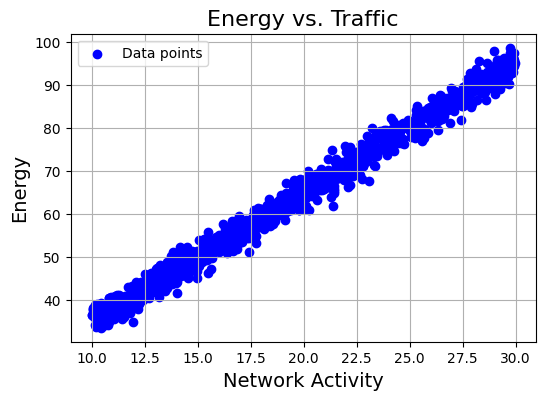

In [34]:
# Load data
data = pd.read_csv('regression.csv')

# Plot the data
plt.figure(figsize=(6, 4))
plt.scatter(data['Net_Activity'], data['Energy'], c='blue', label='Data points')
plt.grid(True)
plt.xlabel('Network Activity', fontsize=14)
plt.ylabel('Energy', fontsize=14)
plt.title('Energy vs. Traffic', fontsize=16)
plt.legend()
plt.show()

In [35]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

### Fetching the data

In [36]:
df_regression = pd.read_csv("regression.csv")
df_regression.columns = df_regression.columns.str.lower()
df_regression

,net_activity,energy
0,29.727959,98.734936
1,18.387504,61.864174
2,29.702529,92.981093
3,10.068594,37.812159
4,29.900919,96.367002
...,...,...
995,10.003400,36.311534
996,14.248588,51.047544
997,27.327307,87.074058
998,20.051893,61.064651


### Splitting x and y into trainig and test set

In [37]:
x = df_regression["net_activity"]

x_train = x.iloc[:700].tolist() # Training on 70 % on data
x_test = x.iloc[700:].tolist()

x_train = np.array(x_train) 
x_test = np.array(x_test)
print(len(x))

1000


In [38]:
y = df_regression["energy"]
y_train = y.iloc[0:700] # Training on 70 % on the data 
y_test = y.iloc[700:]

y_train = np.array(y_train)
y_test = np.array(y_test)

print(len(y_train))

700


### Testing implementation of linear model

In [39]:
lm = LinearRegression(x_train = x_train, y_train = y_train, x_test = x_test, y_test = y_test)

In [40]:
lm.fit()

In [41]:
print(lm.beta_0, lm.beta_1)

1.0115615971565564 3.184505414495466


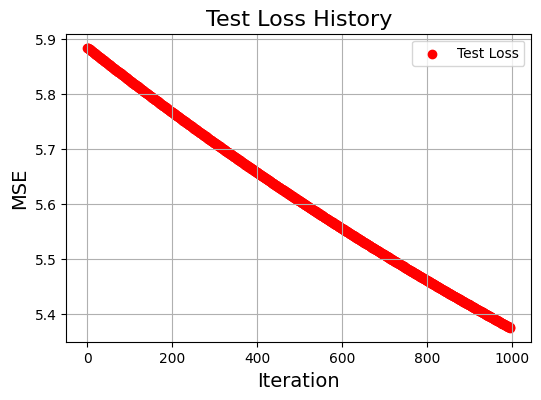

In [42]:
lm.plot_test_loss()

### ❓ Is the training loss curve stable?

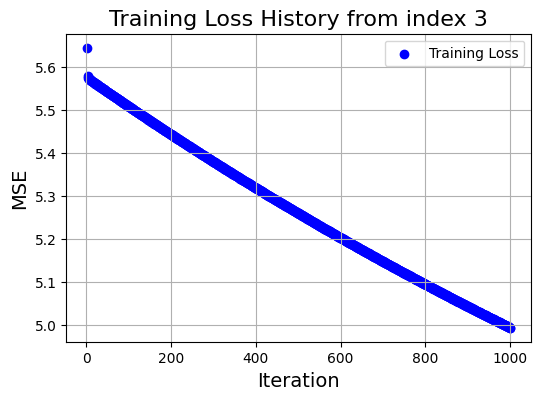

In [43]:
lm.plot_training_loss(from_index = 3) # Plot is difficult to interpret if we include the loss from first iterations of gradient descent 

The training loss seems to be going downward steadily, so yes, the training loss curve is stable. 

### ❓ Derive the resulting energy consumption formula
#### Answer
We assume the linear regression model

\begin{equation*}

\mathbf{Y} = X\mathbf{\beta} + \mathbf{\varepsilon}, \qquad \mathbf{Y} \in \mathbb{R}^n, \quad X \in \mathbb{R}^{n \times p}, \quad \mathbf{\beta} \in \mathbb{R}^p,
\quad \mathbf{\varepsilon} \sim N_n(0, \sigma^2 I_n).
\end{equation*}

To obtain an analytical solution for the parameters $\mathbf{\beta}$, we use maximum likelihood estimation (MLE) 

The likelihood function (in matrix notation) is given by
\begin{equation*}
L(\mathbf{\beta}, \sigma^2) = \frac{1}{(2\pi\sigma^2)^{n/2}} \exp\left(-\frac{1}{2\sigma^2}(\mathbf{Y} - X\mathbf{\beta})^\top(\mathbf{Y} - X\mathbf{\beta})\right).
\end{equation*}

Taking the log, we obtain the log-likelihood function
\begin{equation*}
\ell(\mathbf{\beta}, \sigma^2) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}(\mathbf{Y} - X\mathbf{\beta})^\top(\mathbf{Y} - X\mathbf{\beta}).
\end{equation*}

The score vector is the gradient of the log-likelihood function with respect to $\mathbf{\beta}$
\begin{equation*}
\mathbf{U}(\mathbf{\beta}) = \frac{\partial \ell(\mathbf{\beta}, \sigma^2)}{\partial \mathbf{\beta}} = \frac{1}{\sigma^2} X^\top (\mathbf{Y} - X\mathbf{\beta}).
\end{equation*}

To find the maximum likelihood estimator, we equate the score vector to zero
\begin{equation*}
\mathbf{U}(\mathbf{\beta}) = 0 \implies X^\top (\mathbf{Y} - X\mathbf{\beta}) = 0 \implies X^\top X \mathbf{\beta} = X^\top \mathbf{Y},
\end{equation*}

and solve for $\mathbf{\beta}$, which gives us our maximum likelihood estimator.

\begin{equation*}

\hat{\mathbf{\beta}}_{MLE} = (X^\top X)^{-1} X^\top \mathbf{Y}.
\end{equation*}

Thus, our formula is given by:
\begin{equation*}
\hat{\mathbf{Y}} = X \hat{\mathbf{\beta}}_{MLE} = X (X^\top X)^{-1} X^\top \mathbf{Y} = \mathbf{H} \mathbf{Y}, \quad \mathbf{H} = X (X^\top X)^{-1} X^\top,
\end{equation*}

where $\mathbf{H}$ is a projection matrix which project the observed values $\mathbf{Y}$ onto the column space of $X$. Note that in linear regression with gaussian errors, the maximum likelihood estimator for $\mathbf{\beta}$ is the same as the least squared estimator for $\mathbf{\beta}$.

Of course, we straight up ignore this and rather proceed with numerical optimization of the loss function (MSE) to find an estimator for $\mathbf{\beta}$, $\hat{\mathbf{\beta}}_{gd}$, where $\hat{\mathbf{\beta}}_{gd}$ solves the optimization problem 

\begin{equation*}
\hat{\mathbf{\beta}}_{gd} = \arg\min_{\mathbf{\beta}} \frac{1}{n} \sum_{i=1}^{n} (y_i - \mathbf{x}_i^\top \mathbf{\beta})^2.
\end{equation*}

Note that I prefer not having the factor $\frac{1}{2}$ in my loss function, as it in my opinion abuses the name Mean Squared Error, which is the average of the squared errors, not half of it.


### ❓ Analyze prediction error distribution. What is an unbiased estimator?

#### Answer
When analyzing the prediction error, we compare the predictions from our test-data with the actual response of our test-data

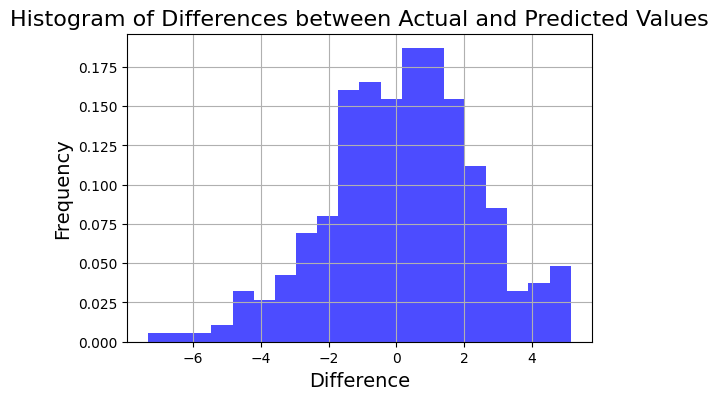

In [44]:
y_pred_test = lm.predict(lm.x_test)
y_test = lm.y_test

difference = y_test - y_pred_test

# Histogram of difference array
plt.figure(figsize=(6, 4))
plt.hist(difference, bins=20, color='blue', alpha=0.7, density=True)
plt.title('Histogram of Differences between Actual and Predicted Values', fontsize=16)
plt.xlabel('Difference', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(True)
plt.show()

As we see in the plot, the errors are quite evenly distributed around 0, and the errors seem to follow a somewhat normal distribution. Since the mean of the errors seems to lie around zero, this supports the fact that our estimator for $\mathbf{Y}$ is indeed unbiased. 

An estimator $\hat{\theta}$ for an unknown parameter $\theta$ is unbiased if and only if 
\begin{equation}
E\left(\hat{\theta}\right) = \theta
\end{equation}

### ❓ What does it tell you when the gradient in SGD is close to zero?
#### Answer
This means that we have found a local minimum of our loss function. If the loss function is convex, then this must also be the global minimum, and we should choose the parameter values $(\beta_0, \beta_1)$ corresponding to that value of the loss function.

## 🔋 Problem 2: Logistic regression

### Your task
1. Implement logistic regression
2. Train your model on binary classification data
3. Engineer features to improve the model's performance

### Formal requirements
1. **Implementation**:
   - Same as before, use standard libraries
   - Implement gradient descent

2. **Performance**: Achieve at least **0.88** classification accuracy on the test set

3. **Discussion**:
   - Explain poor initial performance and your improvements
   - What is the model's inductive bias. Why is it important?
   - Plot the ROC curve, what does the area under the curve measure?

In [45]:
data = pd.read_csv('classification.csv')
train = data[data['split'] == 'train']
test = data[data['split'] == 'test']

### Dataprep

In [46]:
x_train = np.array(train[["x0", "x1"]])
y_train = np.array(train["y"])

x_test = np.array(test[["x0", "x1"]])
y_test = np.array(test["y"])

In [47]:
print(len(x_train))
print(len(y_train))
print(len(x_test))
print(len(x_test))

500
500
500
500


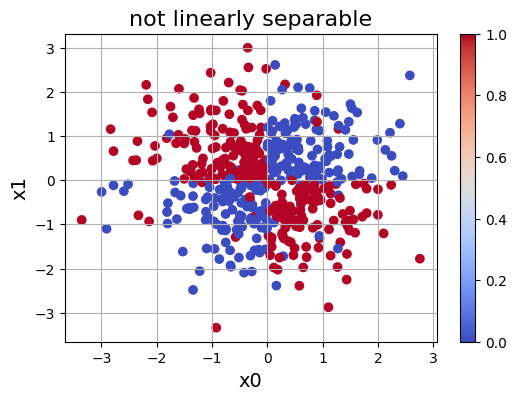

In [48]:
# visualize x0 and x1 of train on scatterplot with colors corresponding to y
plt.figure(figsize=(6, 4))
plt.scatter(train['x0'], train['x1'], c=train['y'], cmap='coolwarm')
plt.grid(True)
plt.xlabel('x0', fontsize=14)
plt.ylabel('x1', fontsize=14)
plt.title('not linearly separable', fontsize=16)
plt.colorbar()
plt.show()

In [49]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

In [50]:
lr = LogisticRegression(x_train = x_train, y_train = y_train, x_test = x_test, y_test = y_test)
lr.fit()

In [51]:
print(lr.beta_0, lr.beta_1, lr.beta_2)

0.09201902857164844 -0.14360323901593489 0.0062552075396334


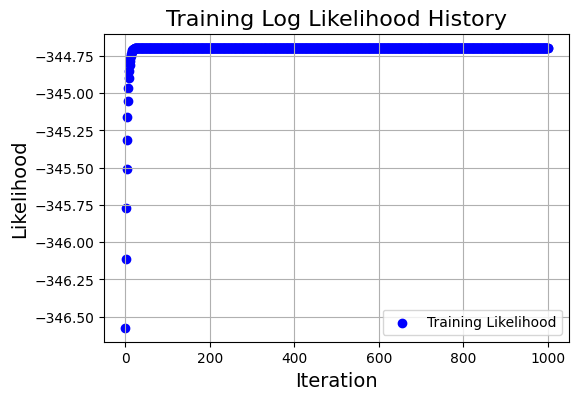

In [52]:
lr.plot_training_loss_history()

In [53]:
lr.predict()

array([ True,  True, False, False,  True,  True,  True,  True,  True,
       False,  True,  True, False, False, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False, False, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
       False,  True, False, False,  True,  True,  True, False,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True, False, False,  True,
        True,  True,  True,  True,  True, False,  True, False,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True,  True,  True,  True,  True,
       False,  True, False, False, False,  True,  True,  True, False,
        True,  True,  True, False,  True,  True, False,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True, False,
       False,  True,

In [54]:
lr.calculate_prediction_accuracy()

np.float64(0.49)

### Investigating feature engineering

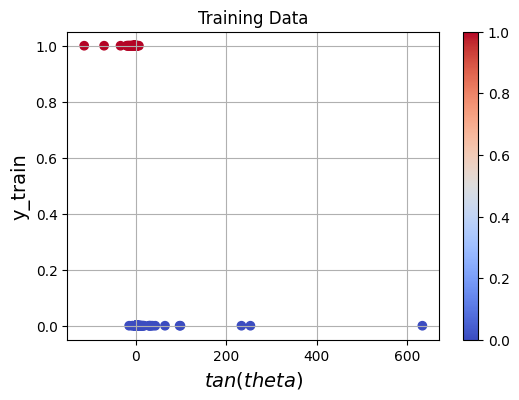

In [55]:
# The first two columns of x_train 
x0 = x_train[:, 0]
x1 = x_train[:, 1]

tan = x1 / x0

# Scatterplot of y_train as a functin of tan with colors corresponding to y_train
plt.figure(figsize=(6, 4))
plt.scatter(tan, y_train, c=y_train, cmap='coolwarm')
plt.grid(True)
plt.xlabel('$tan(theta)$', fontsize=14)
plt.ylabel('y_train', fontsize=14)
plt.title('Training Data')
plt.colorbar()
plt.show()


### Implementing feature engineering
I make another class for handling the next feature. Mostly copy-paste

In [56]:
# Adding a third column to x_train which is the second column divided by the first column
tan = x_train[:, 1] / x_train[:, 0]
x_train = np.column_stack((x_train, tan))

# Adding a third column to x_test which is the second column divided by the first column
tan = x_test[:, 1] / x_test[:, 0]
x_test = np.column_stack((x_test, tan))


In [57]:
lr2 = LogisticRegression2(x_train = x_train, y_train = y_train, x_test = x_test, y_test = y_test)
lr2.fit()

In [58]:
print(lr2.beta_0, lr2.beta_1, lr2.beta_2, lr2.beta_3)
print(lr2.calculate_prediction_accuracy())

0.12517618976637299 -0.1356967492719477 0.1761406131615476 -1.3198639961915206
0.904


### ❓ Explain poor initial performance and your improvements
#### Answer

To begin with, we model the relationship between x and y the following way

\begin{equation*}
Y_i \sim \text{Bernoulli} \left(p =  \sigma(\eta_i) \right),
\end{equation*}

where $\sigma$ represents the sigmoid function, or the inverse of the $\textit{logit}$ function, and $\eta_i = X_i^T\beta$ is our linear predictor.
In other words, we assume there exists a linear relationship between the covariates and $\textit{logit}(p)$. It is clear from the plot in our case that that is not true. It is easy to see, however that the points are blue in the first and third quadrant of the coordinate system, or in other words, where the tangent of the angle from the origin is positive. That is if we let

\begin{equation*}
\begin{aligned}
r &= \sqrt{x_0^2 + x_1^2} \\
\theta &= \text{arctan}\left( \frac{x_1}{x_0}\right),
\end{aligned}
\end{equation*}

we have that most of the points seem to be blue where $\tan(\theta) > 0$. So it makes sense to include the parameter $\tan(\theta) = \frac{x_1}{x_2}$ in the model, and that is the only feature engineering that I did. I Included this as a quantitative covariate, but I could howerver, have added the categorical variable $TanIsPositive$ which is one if $\tan(\theta)$ is positive, and zero otherwise.



### ❓ What is the model's inductive bias? Why is it important?
#### Answer
The inductive bias of a model is the set of assumptions that the model makes about the underlying data distribution. In the case of logistic regression, the inductive bias is that the relationship between the input features and the log-odds of the target variable is linear. This means that logistic regression assumes that the logit transformation of the probability of the positive class can be expressed as a linear combination of the covariates. This "puts a cap" on the model's flexibility, and thus its performance.


### ❓ What does the area under the ROC curve measure?

#### Answer
The area measures the probability that the model will predict a higher response for a randomly chosen positive datapoint than for a randomly chosen negative datapoint.